<a href="https://colab.research.google.com/github/alejolion57-stack/Portafolio_Alejandro-Leon/blob/main/Perfil_de_consumidor_food_delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
**🍔Perfil de consumidor food delivery🍕**
--
---
Dataset: Kaggle

**Objetivo:**
Hacer un perfil de cliente en un ecommers basados en un dataset cmpuesto por información demográfica: Age,	Gender,	Marital Status,	Occupation,	Monthly Income,	Educational Qualifications,	Family size,	Customer Type,	latitude,	longitude,	Pin code,	Output,	Feedback

**Métricas KPIs:**
 - Edad promedio de clientes
 - Ocupación
 - Escolarridad
 - Distribución por género
 - Ingreso promedio Vs Educación
 - Tipo de cliente Vs. ingreso mensual
 - Tipo de cliente Vs.Feedback
 - Grado de satisfacción por edad, género y nivel de ingresos

**Plan de trabajo:**
1. Exploracion inicial de datos
2. Limpieza del dataset:
   - Manejo de duplicados en las filas con índices 205, 332 y 348 .
   - Validación de Código postal inconsistente. Aparece 560034, 560070 y 56.
     El valor 56 podría estar truncado o ser un dato incorrecto.
   - Eliminación de columna error Unnamed 13.
   - Validación, estandarización y correción ortográfica de la columna Ocupation.
  

3. Exportación del dataset límpio.
4. Diseño del dashboard en Power BI



**1️⃣Exploración inicial de los datos**
--
---

In [6]:
import pandas as pd
df = pd.read_csv("perfil food delivery.csv")
df.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    object 
 2   Marital Status              388 non-null    object 
 3   Occupation                  388 non-null    object 
 4   Monthly Income              388 non-null    object 
 5   Educational Qualifications  388 non-null    object 
 6   Family size                 388 non-null    int64  
 7   Customer Type               388 non-null    object 
 8   latitude                    388 non-null    float64
 9   longitude                   388 non-null    float64
 10  Pin code                    388 non-null    int64  
 11  Output                      388 non-null    object 
 12  Feedback                    388 non-null    object 
 13  Unnamed: 13                 388 non

In [8]:
print(df.isnull().sum())

print("Filas duplicadas:", df.duplicated().sum())

print("Porcentaje duplicado:",
      round(df.duplicated().mean() * 100, 2), "%")

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64
Filas duplicadas: 103
Porcentaje duplicado: 26.55 %


---
2️⃣**Limpieza del Dataset**
--

---
**🤔🥸Investigamos los duplicados**
--
---

In [9]:
# Mostrar las filas duplicadas, incluyendo la primera aparición
duplicados = df[df.duplicated(keep=False)]

print("Filas involucradas en grupos duplicados:",
      len(duplicados))

display(duplicados.sort_values(
    by=["Age", "Gender"]
).head(5))

Filas involucradas en grupos duplicados: 169


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
205,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes
332,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes
348,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes
226,21,Female,Single,Student,No Income,Post Graduate,3,Regular,12.9149,77.5635,560070,Yes,Positive,Yes
313,21,Female,Single,Student,No Income,Post Graduate,3,Regular,12.9149,77.5635,560070,Yes,Positive,Yes


---
**📑Reviso los registros repetidos**
--
---

In [10]:
df.loc[[205, 332, 348]]

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
205,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes
332,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes
348,20,Male,Single,Student,No Income,Graduate,2,Regular,12.9261,77.6221,560034,Yes,Positive,Yes


In [11]:
"Guardo una copia del dataframe original"
df_original = df.copy()

---
**🚫Elimino los duplicados**
--
---

In [24]:
df = df.drop_duplicates()

In [13]:
print("Filas restantes:", len(df))
print("Duplicados restantes:", df.duplicated().sum())

Filas restantes: 285
Duplicados restantes: 0


---
**📦Valido Código postal**
--
---

In [14]:
"Convierto a texto"
df["Pin code"] = df["Pin code"].astype(str)

In [15]:
codigos = df["Pin code"].astype(str).str.strip()

print(codigos.str.len().value_counts().sort_index())

print(df.loc[~codigos.str.fullmatch(r"\d{6}"), ["Pin code"]])

Pin code
6    285
Name: count, dtype: int64
Empty DataFrame
Columns: [Pin code]
Index: []


---
🚨**Elimino columnas inecesarias**
--
Al ver el head determino que la columna  Unnamed 13 es un error que no aporta nada al análisis y la elimino. Amdemás elimino las columnas dekatitud y longitud, innecesarias para este análisis.

---

In [16]:
df = df.drop(columns=["Unnamed: 13", "latitude", "longitude"])
df.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,Pin code,Output,Feedback
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,560001,Yes,Positive
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,560009,Yes,Positive
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,560017,Yes,Negative
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,560019,Yes,Positive
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,560010,Yes,Positive


---

✅**Valido los datos en las columnas categóricas**
--
---

In [17]:

columnas_categoricas = [
    "Gender",
    "Marital Status",
    "Occupation",
    "Educational Qualifications",
    "Customer Type",
    "Output",
    "Feedback"
]

for columna in columnas_categoricas:
    print(f"\n--- {columna} ---")
    print(df[columna].value_counts(dropna=False))




--- Gender ---
Gender
Male      164
Female    121
Name: count, dtype: int64

--- Marital Status ---
Marital Status
Single               189
Married               87
Prefer not to say      9
Name: count, dtype: int64

--- Occupation ---
Occupation
Student           144
Employee           94
Self Employeed     38
House wife          9
Name: count, dtype: int64

--- Educational Qualifications ---
Educational Qualifications
Graduate         126
Post Graduate    125
Ph.D              21
School            11
Uneducated         2
Name: count, dtype: int64

--- Customer Type ---
Customer Type
Regular     162
Frequent    105
New          18
Name: count, dtype: int64

--- Output ---
Output
Yes    217
No      68
Name: count, dtype: int64

--- Feedback ---
Feedback
Positive     231
Negative      54
Name: count, dtype: int64


---

✅ **Valido la ortografía en la columna *occupation***
--

In [18]:
df["Occupation"].value_counts()

,count
Occupation,
Student,144
Employee,94
Self Employeed,38
House wife,9


En Occupation hay dos categorías cuya escritura se debe normalizar:
- Self Employeed → Self Employed (error ortográfico).
- House wife → Housewife (unificación de escritura).

In [19]:
df["Occupation"] = df["Occupation"].replace({
    "Self Employeed": "Self Employed",
    "House wife": "Housewife"
})

In [20]:
"Prueba"
df["Occupation"].value_counts()

,count
Occupation,
Student,144
Employee,94
Self Employed,38
Housewife,9


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 285 entries, 0 to 386
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         285 non-null    int64 
 1   Gender                      285 non-null    object
 2   Marital Status              285 non-null    object
 3   Occupation                  285 non-null    object
 4   Monthly Income              285 non-null    object
 5   Educational Qualifications  285 non-null    object
 6   Family size                 285 non-null    int64 
 7   Customer Type               285 non-null    object
 8   Pin code                    285 non-null    object
 9   Output                      285 non-null    object
 10  Feedback                    285 non-null    object
dtypes: int64(2), object(9)
memory usage: 26.7+ KB


---
3️⃣**Exporto el dataset Limpio:**
--
1. Se eliminan 103 filas duplicadas correspondientes a registros repetidos por error.
2. Se normalizan lo errores de ortografía en la columna de *ocupación*.
4. Se eliminan las columnas error o inecesarias para este análisis *latitud*, *longitud* *unamed13*.

Nota: el CSV limpio se guarda automáticamente (en colab) como: "perfil food delivery limpio.csv" y lo dscargo para el diseño del dashboard en **Power BI**

---

In [26]:
df.to_csv("perfil food delivery limpio.csv", index=False, encoding="utf-8-sig")

---
**4️⃣ Diseño del dashboard**
--
---

Para este análisis creo un Dashboar en Power Bi con 3 tabgleros que dan una radiografía completa del consumidor del Food delivery, su demografía y su grado de satisfacción con la marca.

1. **General**
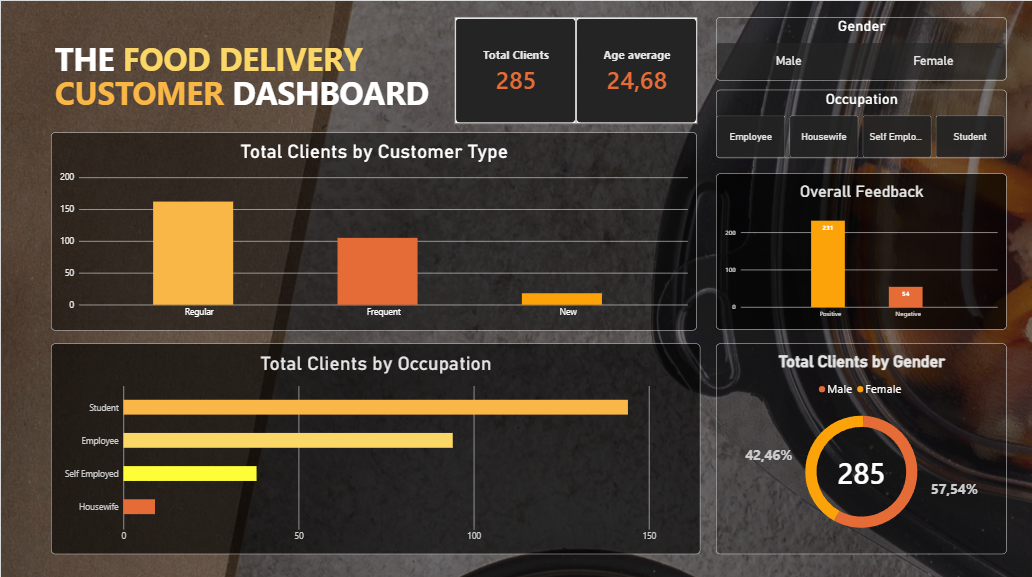

 2. **Demographics**
 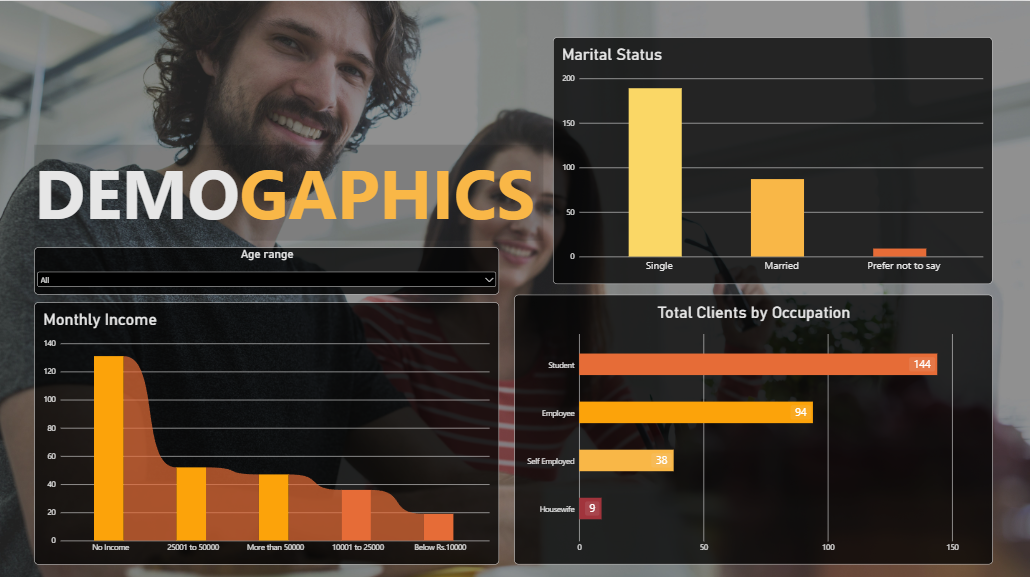



**3. Satisfaction**

---
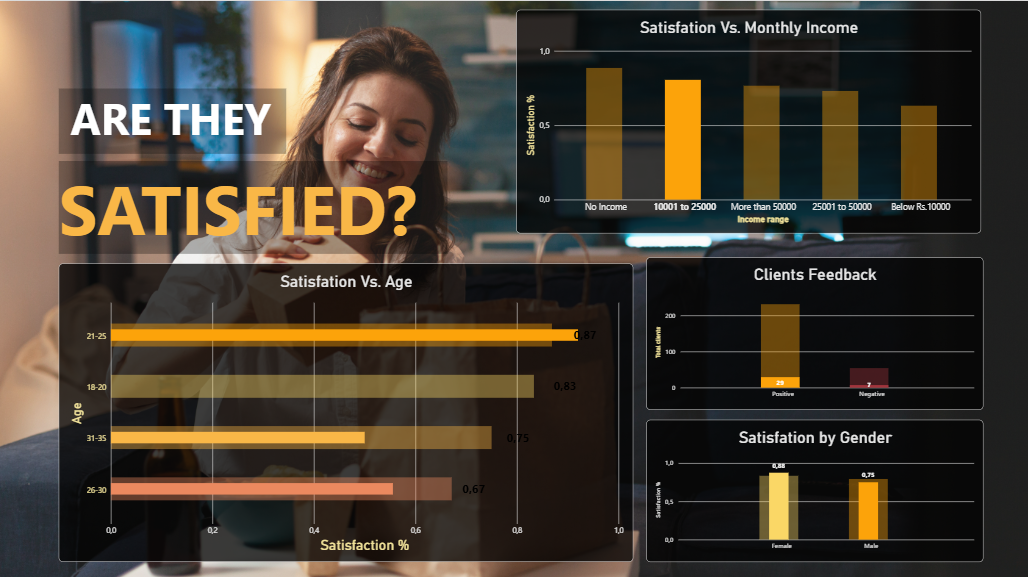

**Contacto**
-
[![LinkedIn](https://img.shields.io/badge/LinkedIn-Alejandro%20León-0077B5?style=for-the-badge&logo=linkedin&logoColor=1E293B)](https://www.linkedin.com/in/alejandrole%C3%B3nospina/)
[![Email](https://img.shields.io/badge/Email-alejolion57%40gmail.com-D14836?style=for-the-badge&logo=gmail&logoColor=white)](mailto:alejolion57@gmail.com)
[![GitHub](https://img.shields.io/badge/GitHub-Portafolio-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/alejolion57-stack)